In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import re

In [62]:
df = pd.read_csv('./Data/standardized_data.csv')
df

,year,month,day,id,user,title,type,maxspeed100,maxspeed500,maxspeednm,...,dislikes,file_id,catid,alias,rating,avatar,spot,conditions,turncount,foilingturncount
0,2021,11,27,0,bwd,XL breakfast,Windfoil,13.32,11.64,4.79,...,0,105,31,xl-breakfast,5.0,NaN,Island View,SE 12-16,9,60
1,2021,1,1,1,tweezer,Drive of Fame,Windfoil,21.72,18.36,16.48,...,0,116,31,drive-of-fame,0.0,NaN,Island View,SE 15-23,82,84
2,2021,1,1,2,bwd,Well hello 2021,Windfoil,13.43,12.34,11.79,...,0,117,31,well-hello-2021,0.0,NaN,Island View,SE 15-25,91,77
3,2021,1,2,3,tweezer,Flocking Ducks,Windfoil,23.42,17.77,16.85,...,0,118,31,flocking-ducks,0.0,NaN,Willows Bch,SE 12-20,57,89
4,2021,1,3,4,tweezer,Boat Chase,Windfoil,21.91,19.54,18.01,...,0,119,31,boat-chase,0.0,NaN,Willows Bch,SSE 12-18,65,95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6165,2026,11,16,1549,tweezer,Race faces,Parawing,17.03,14.21,0.00,...,0,6627,55,race-faces-1,0.0,NaN,Ka'a,ENE 25-40,176,76
6166,2026,11,17,1550,thepope,Calmer Kaa,Wingfoil,16.75,14.58,0.00,...,0,6628,33,calmer-kaa,0.0,NaN,Ka'a,ENE 18-28,210,88
6167,2026,11,17,1551,tweezer,Leroy Brown,Parawing,18.40,16.07,0.00,...,0,6629,55,leroy-brown,0.0,NaN,Ka'a,ENE 20-30,146,66
6168,2026,11,17,1552,rup_dogg,Ka’a_2026-11-17_rup_dogg,Parawing,16.52,14.50,0.00,...,0,6630,55,kaa2026-11-17rupdogg,0.0,NaN,Ka'a,ENE 20-28,104,91


In [45]:
df.groupby('spot').count().sort_values('year', ascending=False).head(30)

,year,month,day,id,user,title,type,maxspeed100,maxspeed500,maxspeednm,...,likes,dislikes,file_id,catid,alias,rating,avatar,conditions,turncount,foilingturncount
spot,,,,,,,,,,,,,,,,,,,,,
Ross Bay,2401,2401,2401,2401,2401,2401,2401,2401,2401,2401,...,2401,2401,2401,2401,2401,2401,0,2401,2401,2401
Nitinat Lk,727,727,727,727,727,727,727,727,727,727,...,727,727,727,727,727,727,0,727,727,727
[Secret spot],468,468,468,468,468,468,468,468,468,468,...,468,468,468,468,468,468,0,468,468,468
Cattle Pt,414,414,414,414,414,414,414,414,414,414,...,414,414,414,414,414,414,0,414,414,414
Clover Pt,407,407,407,407,407,407,407,407,407,407,...,407,407,407,407,407,407,0,407,407,407
Willows Bch,342,342,342,342,342,342,342,342,342,342,...,342,342,342,342,342,342,0,342,342,342
Comox Spit,325,325,325,325,325,325,325,325,325,325,...,325,325,325,325,325,325,0,325,325,325
Island View,157,157,157,157,157,157,157,157,157,157,...,157,157,157,157,157,157,0,157,157,157
China Ck,153,153,153,153,153,153,153,153,153,153,...,153,153,153,153,153,153,0,153,153,153


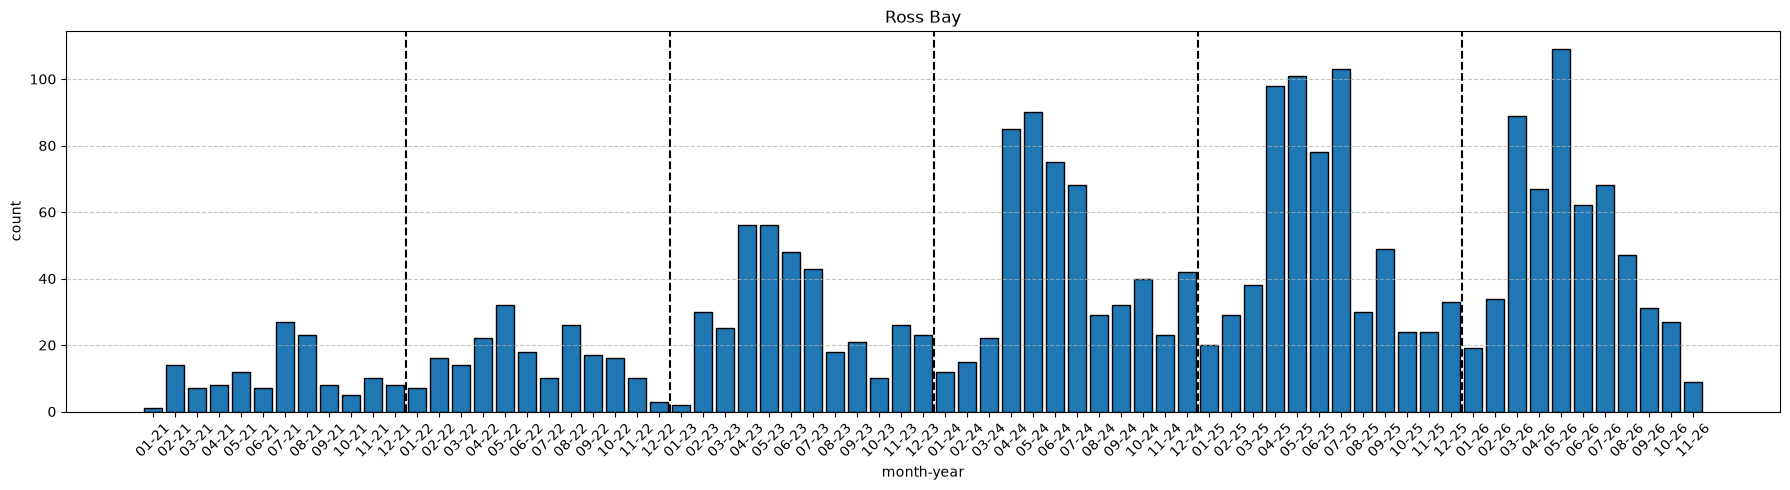

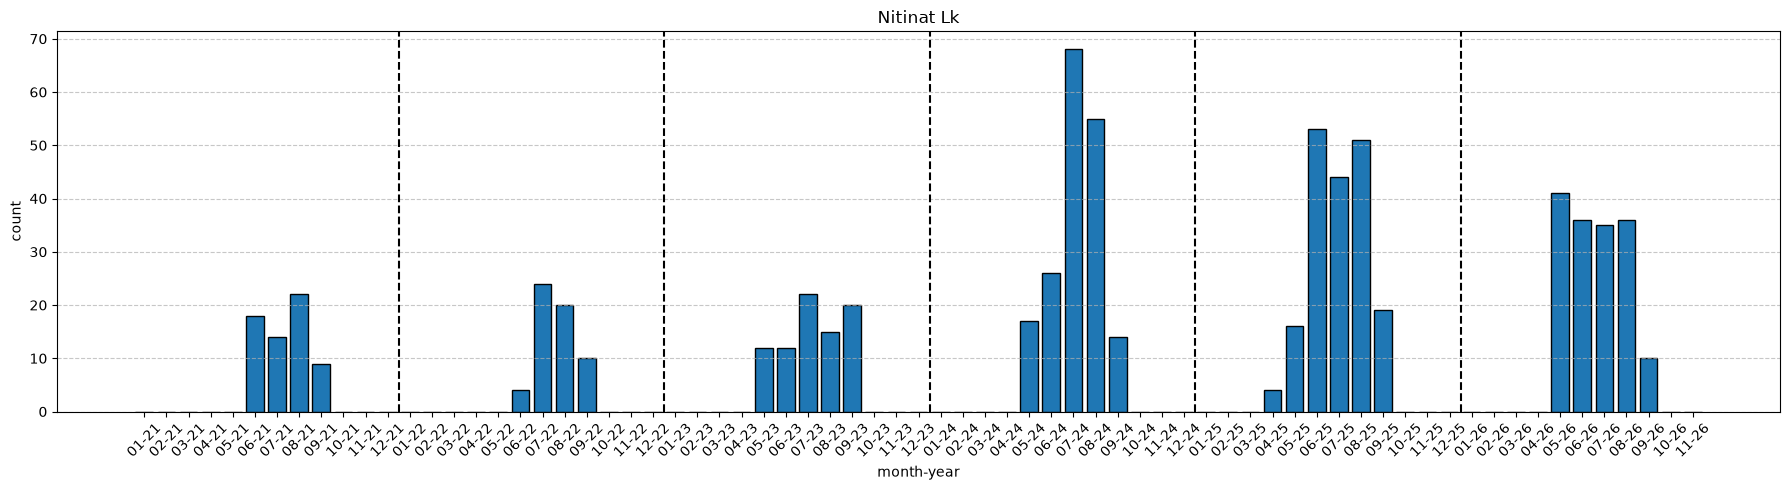

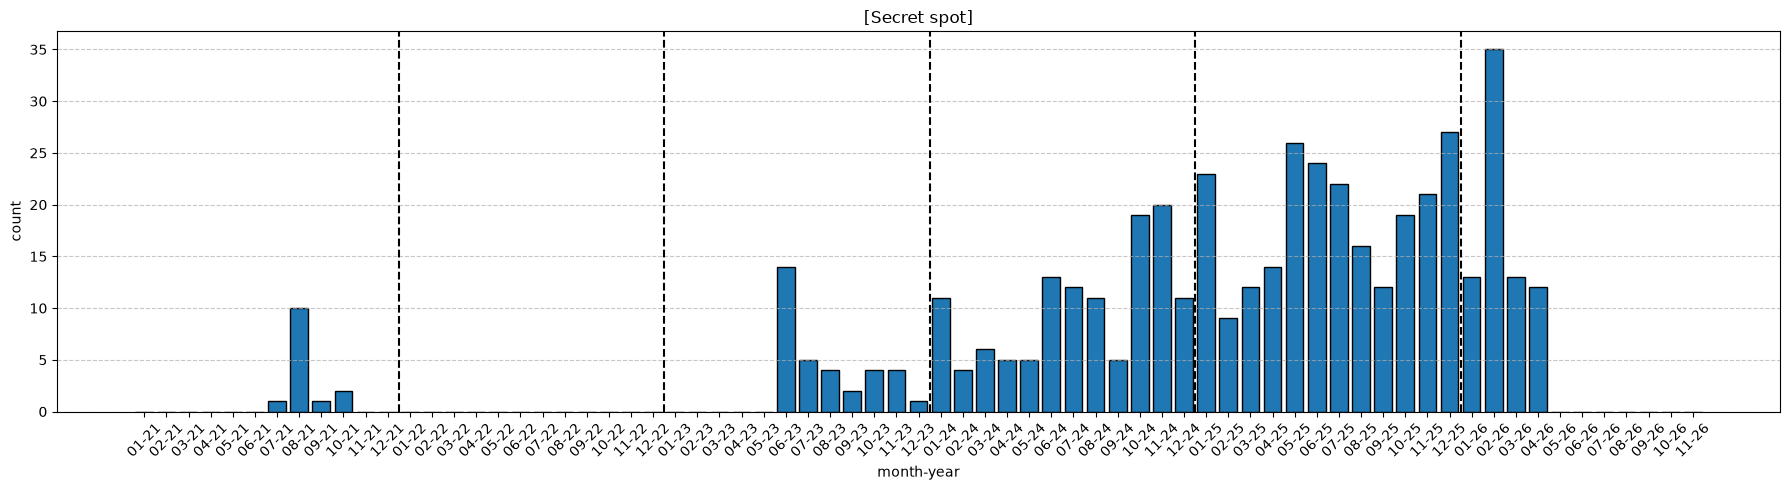

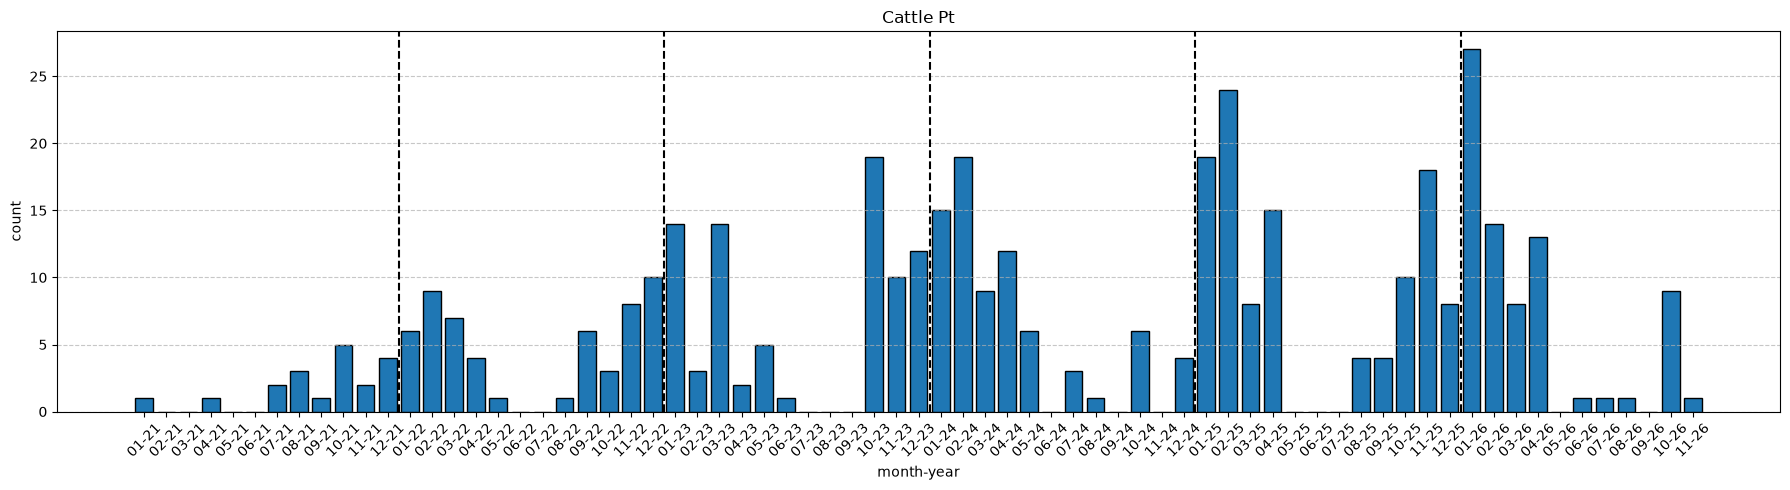

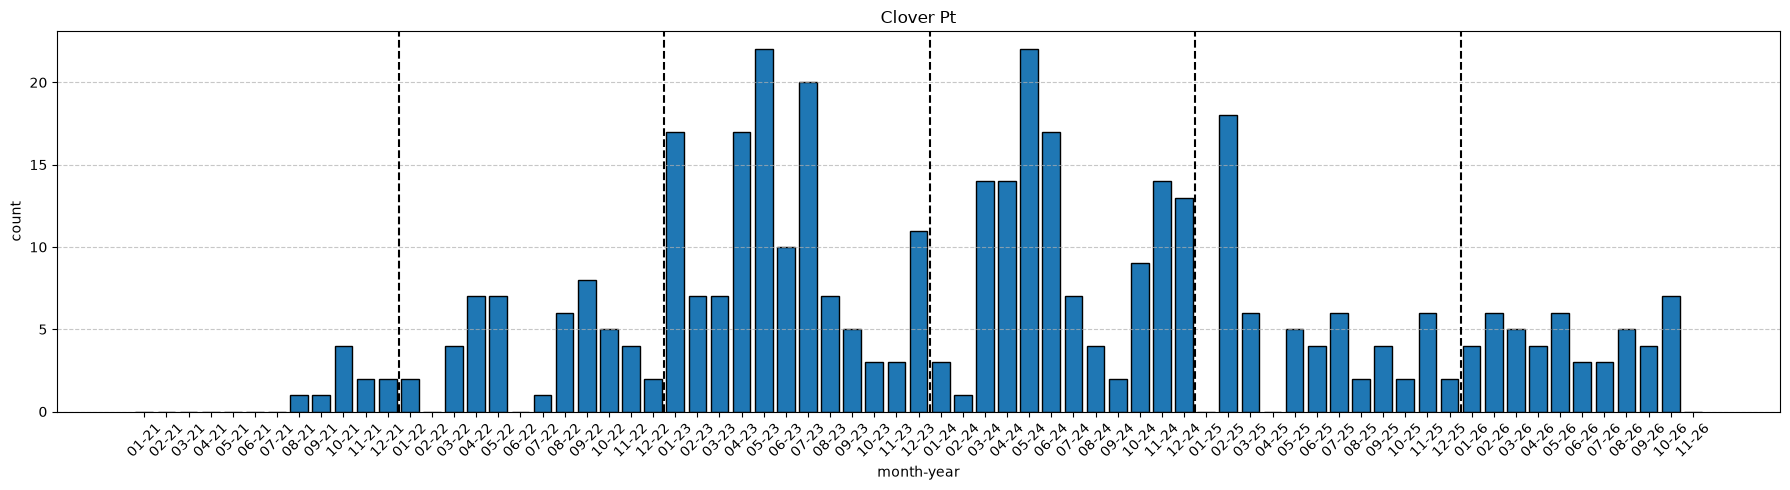

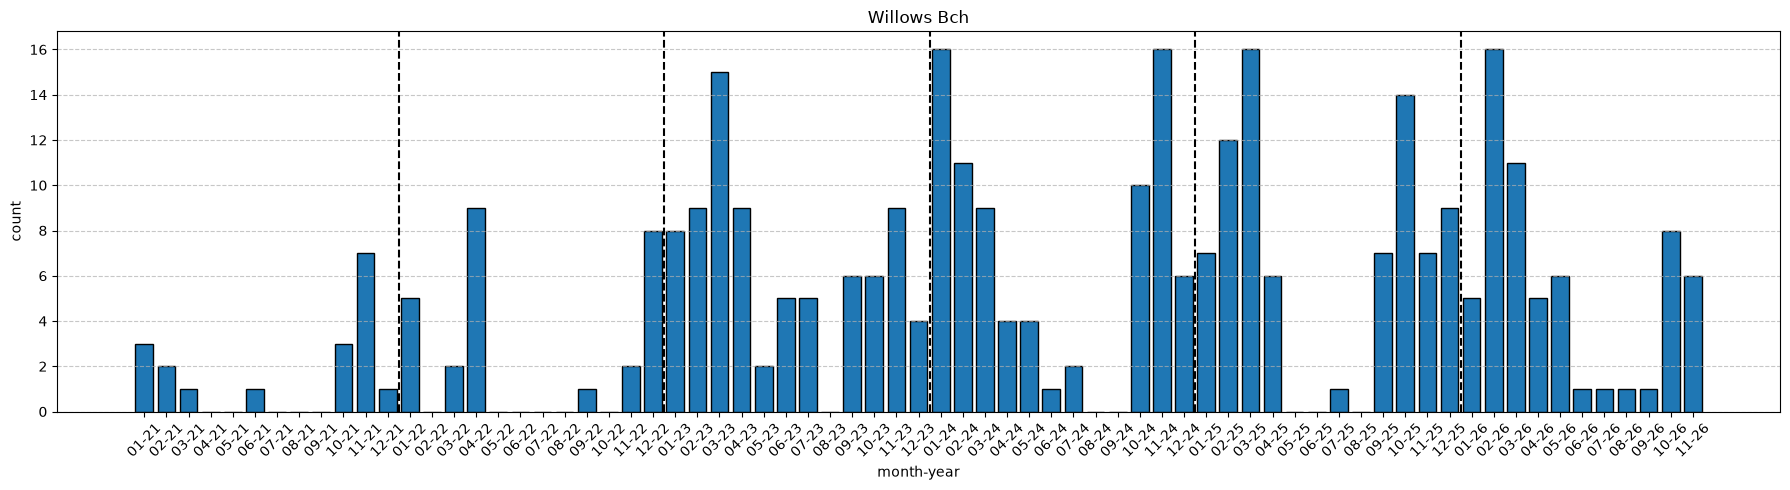

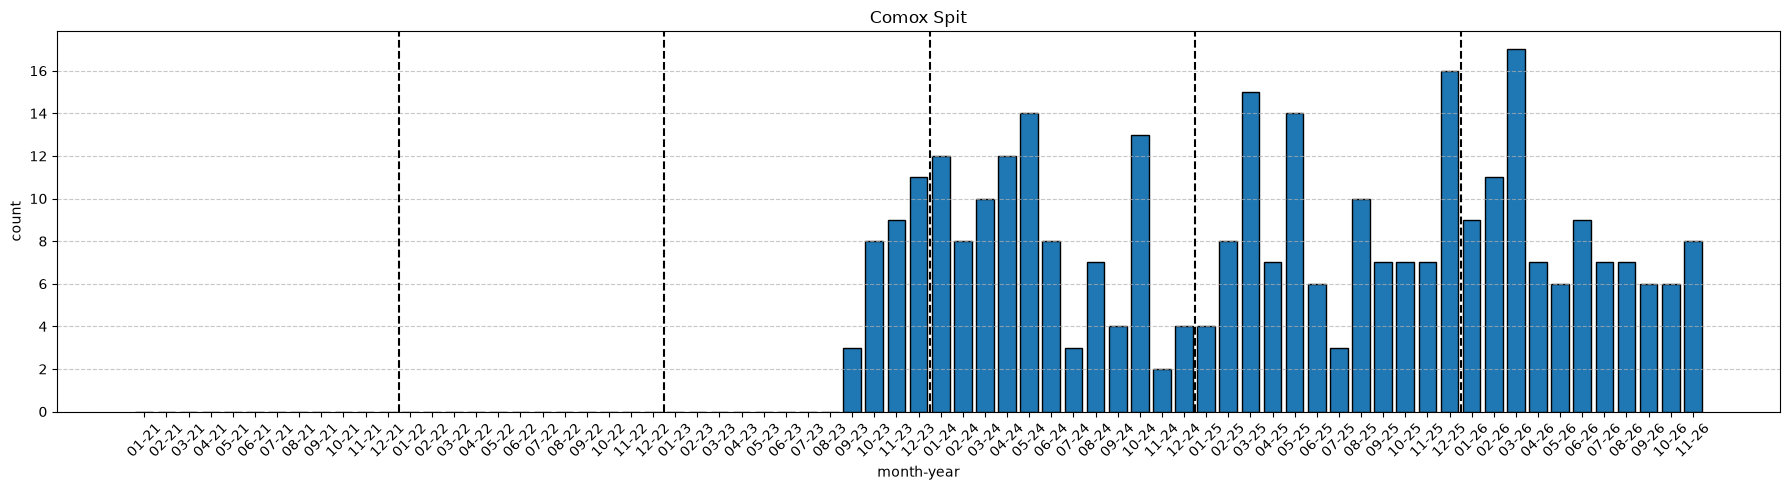

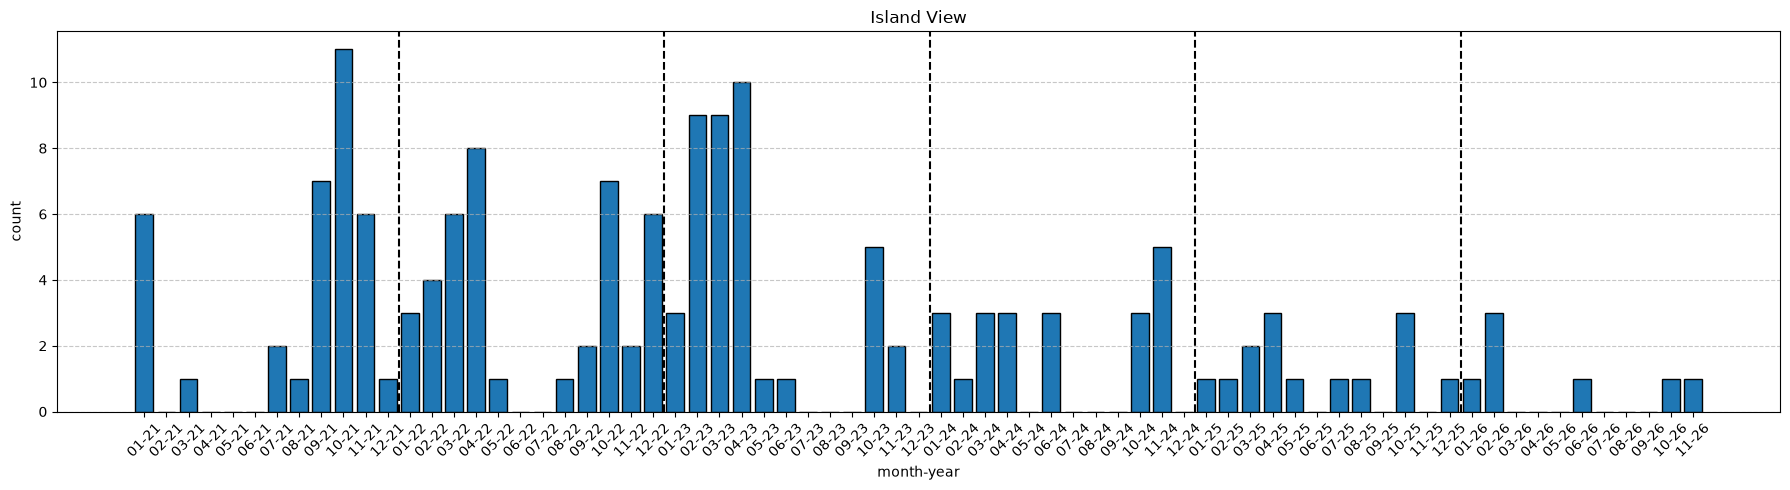

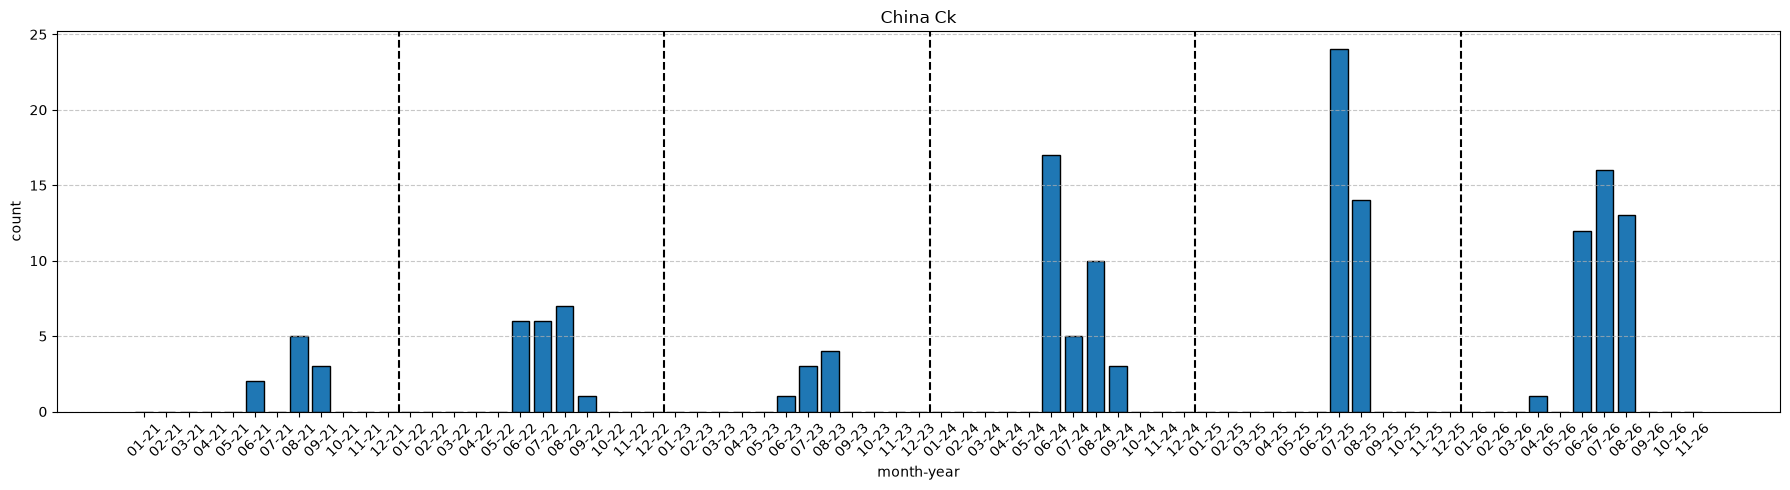

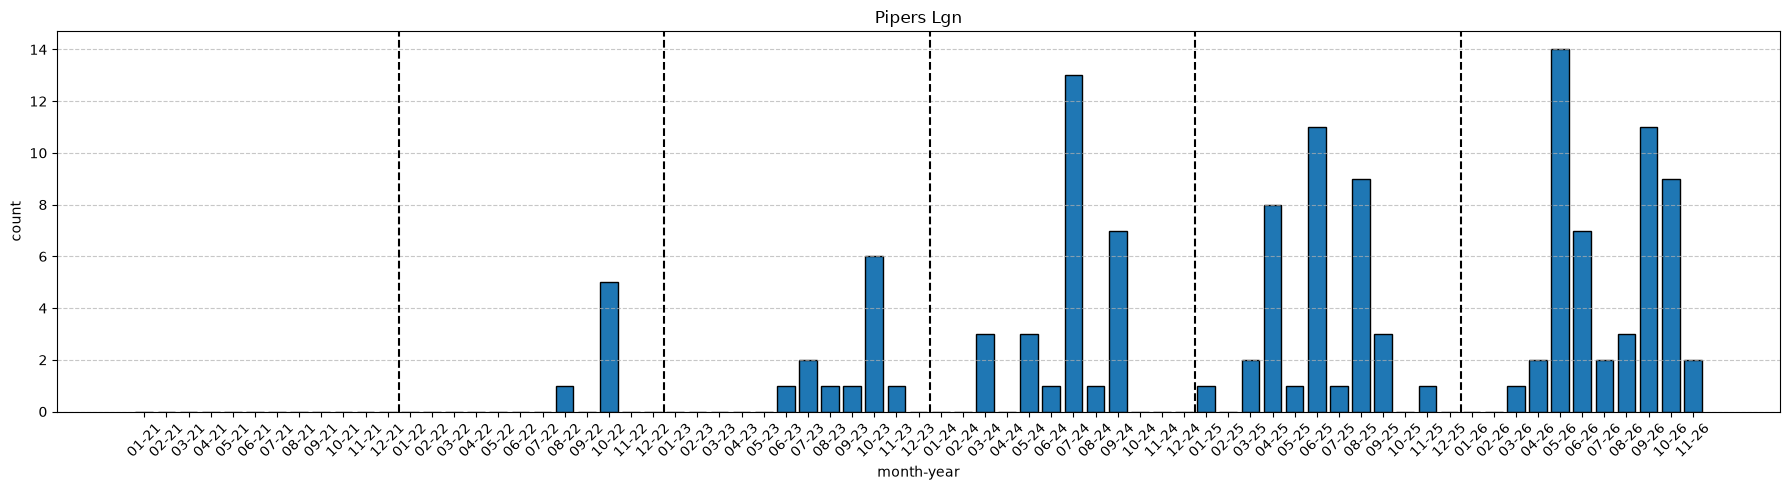

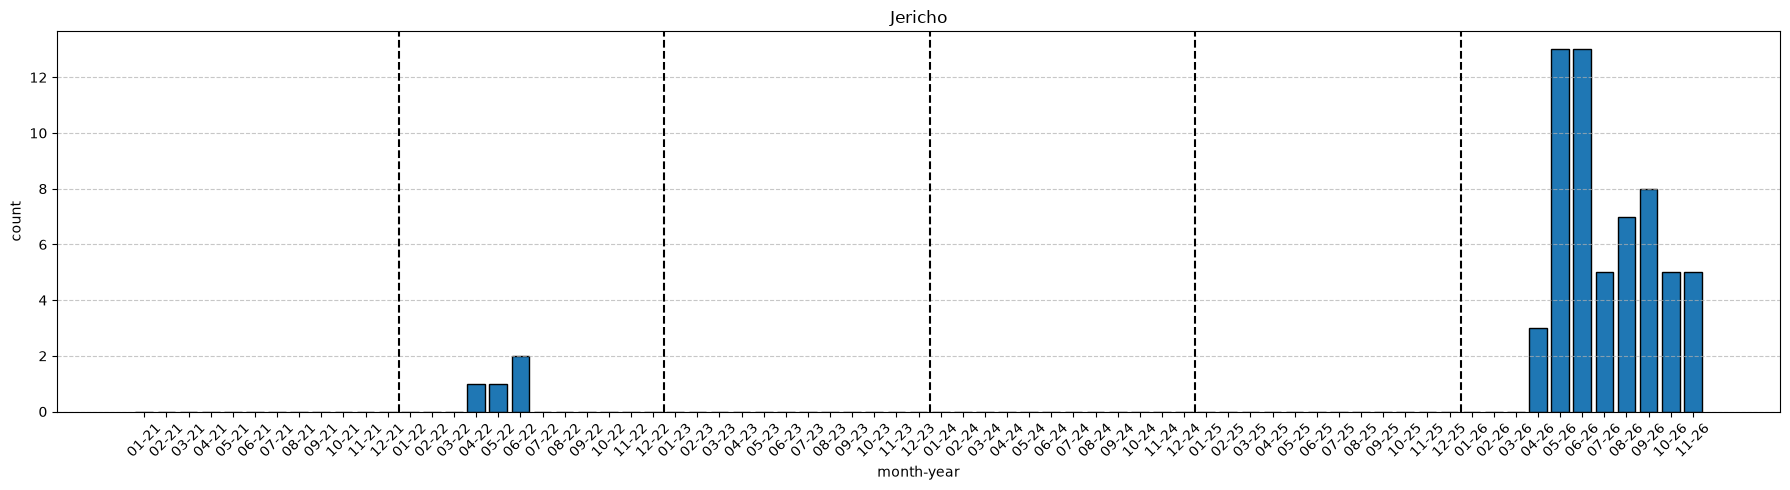

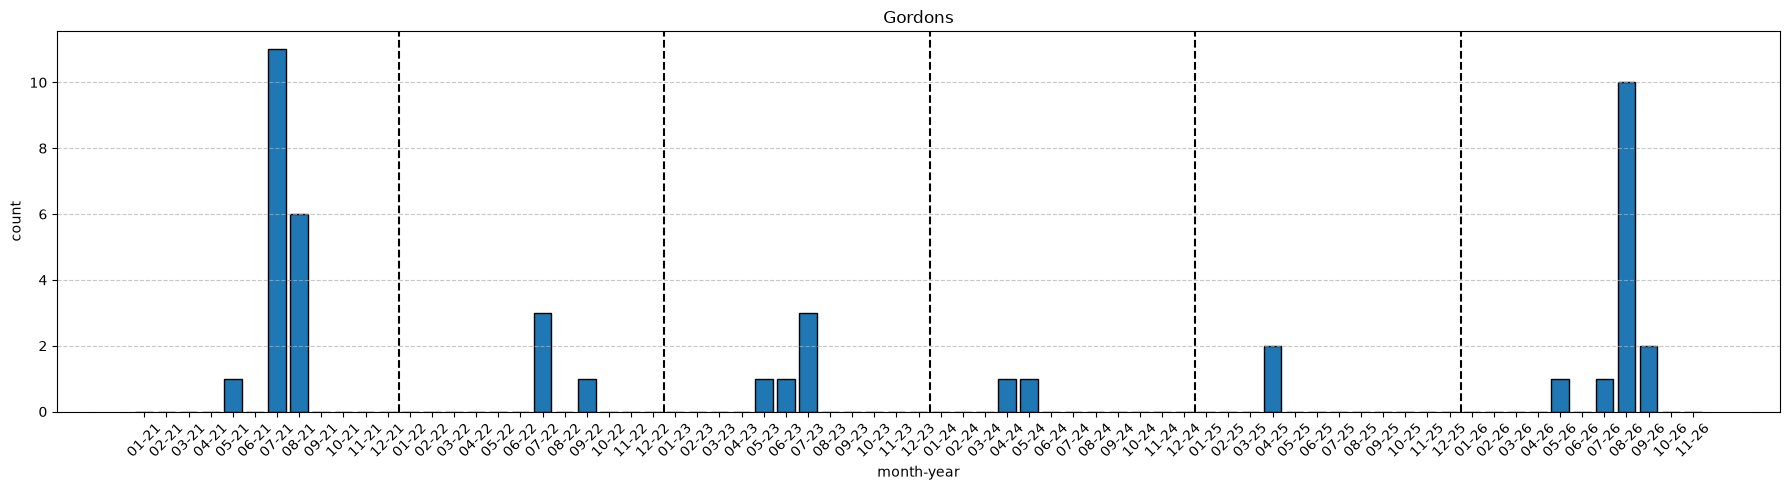

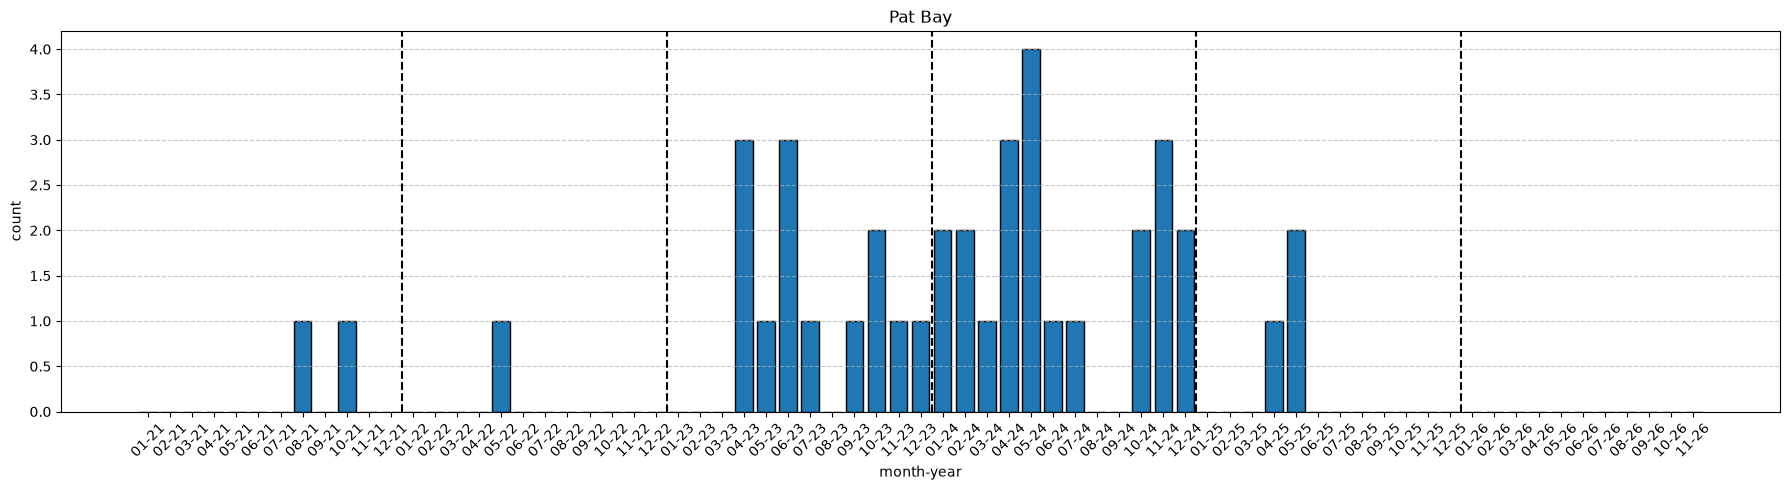

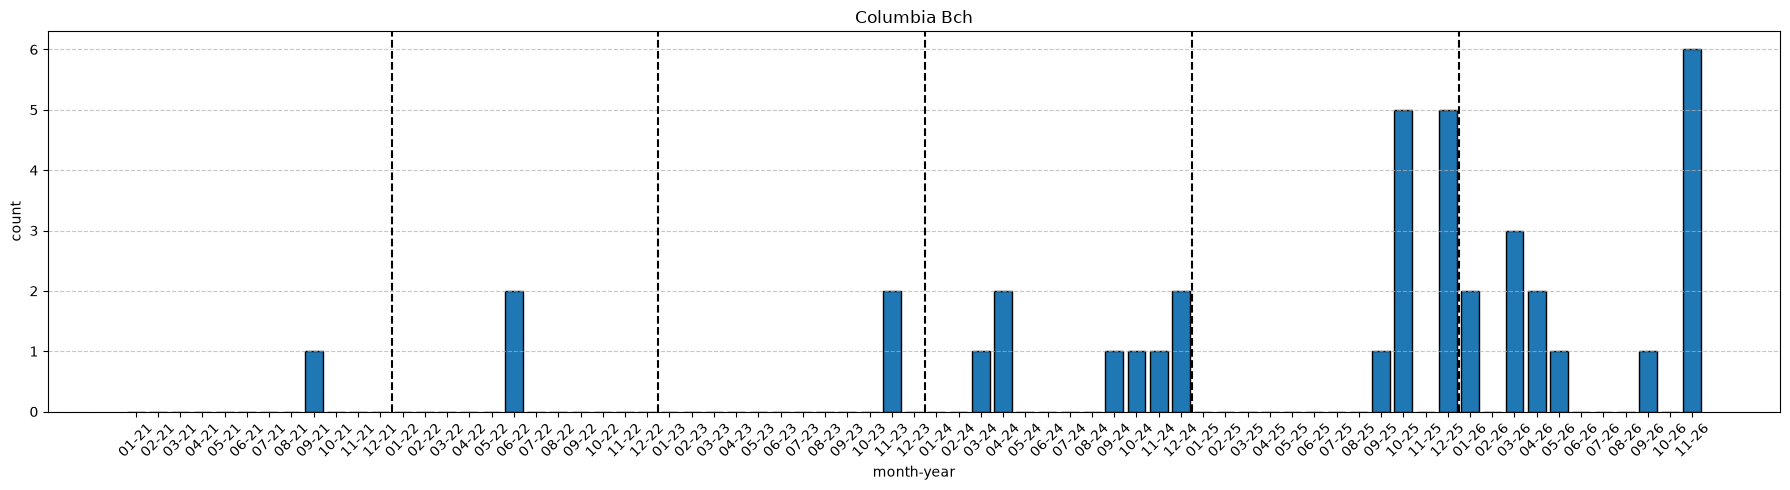

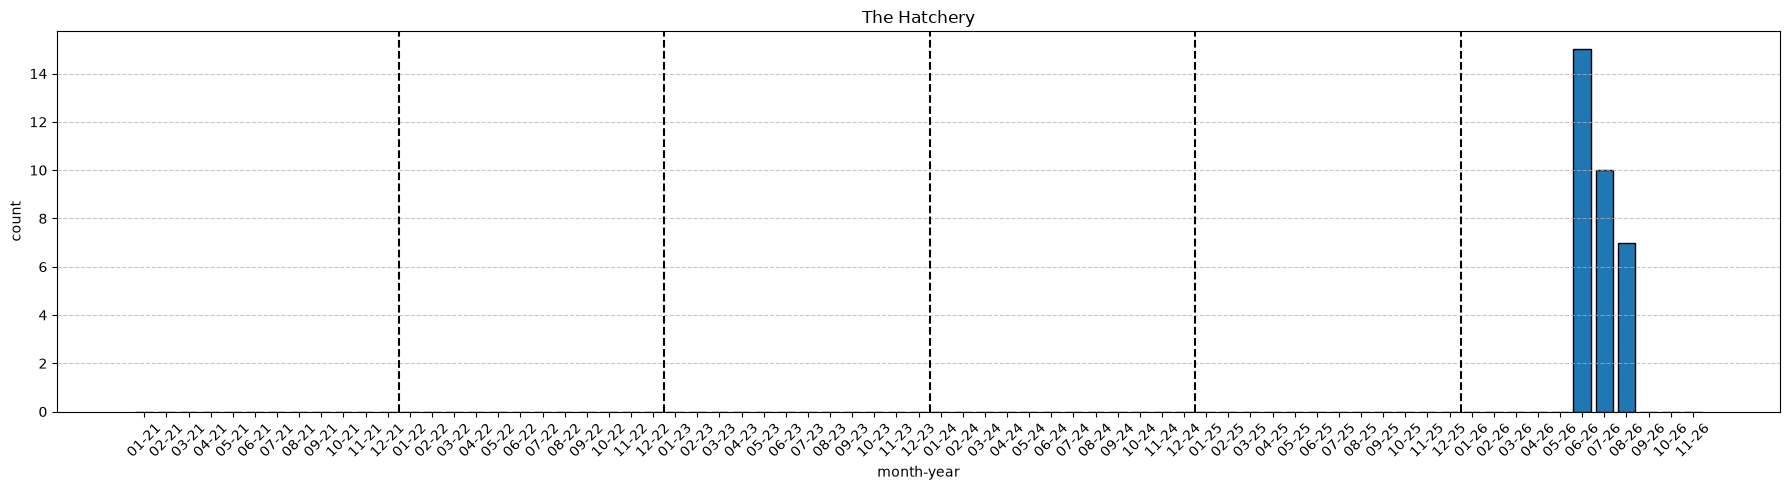

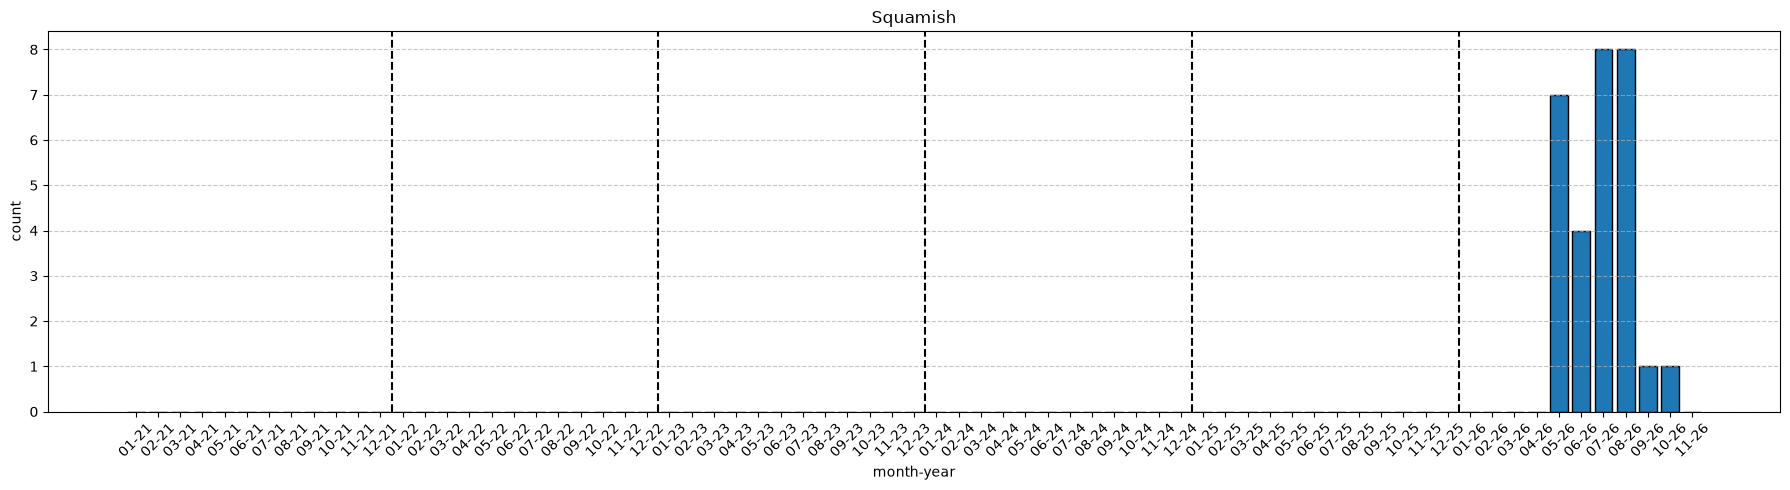

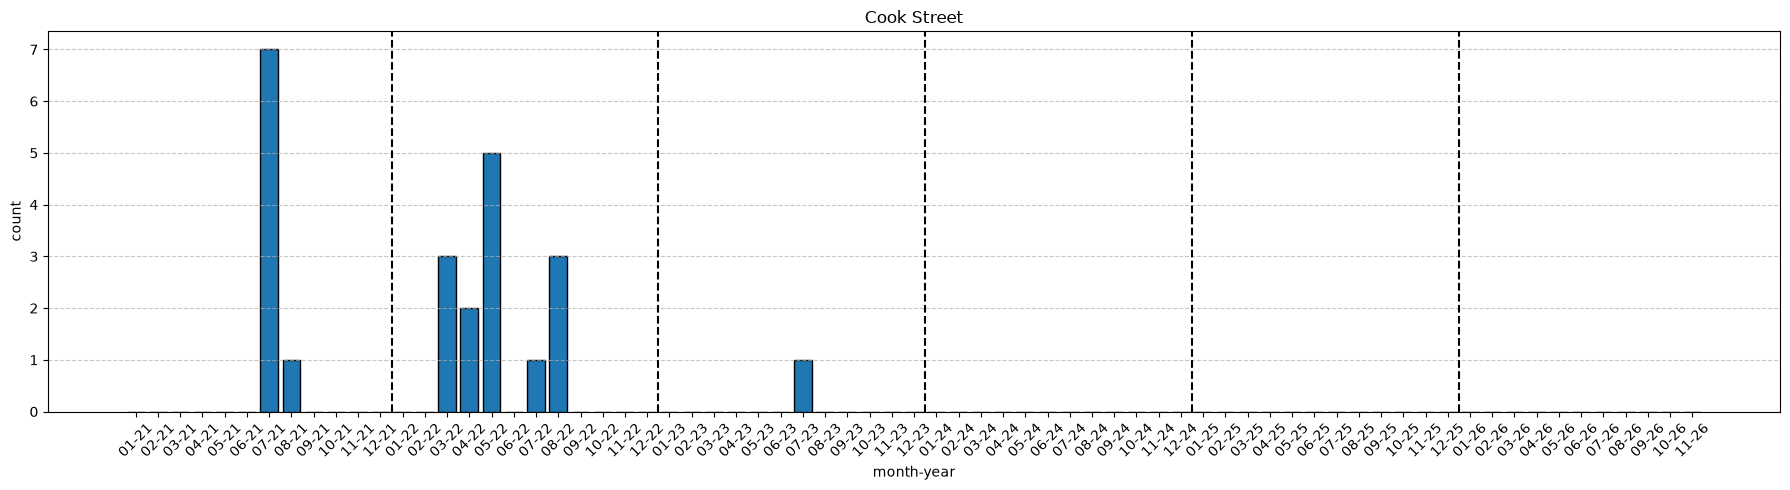

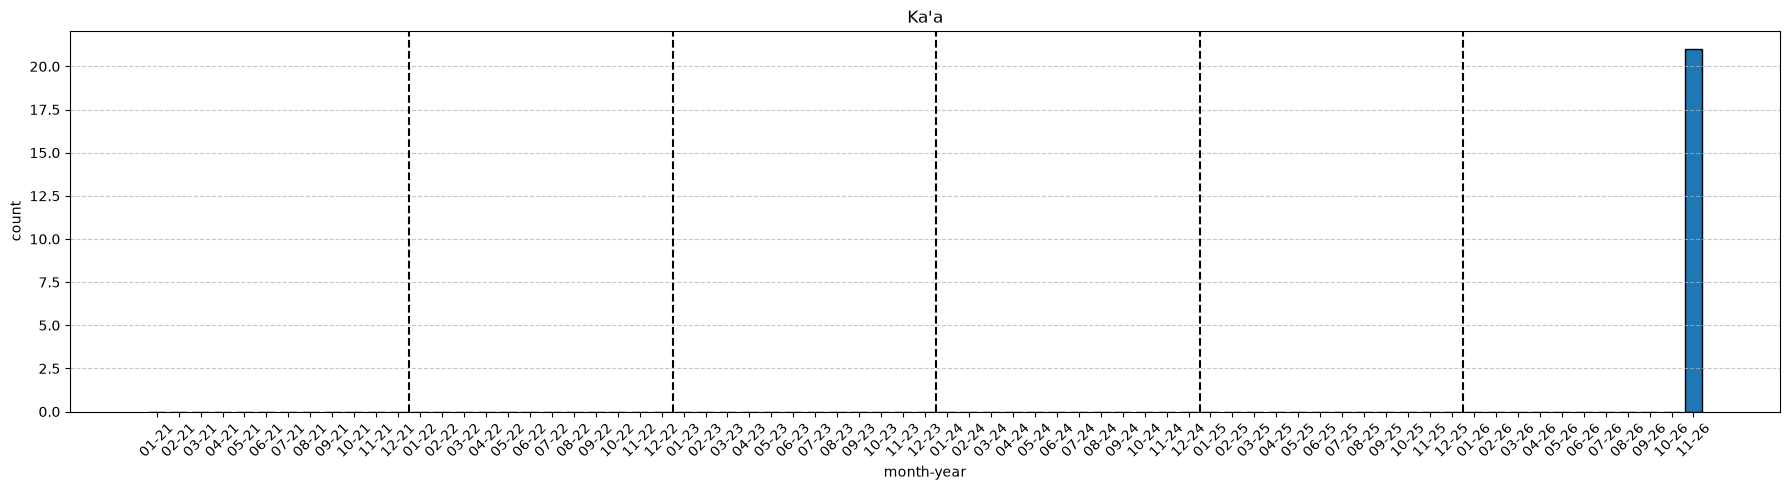

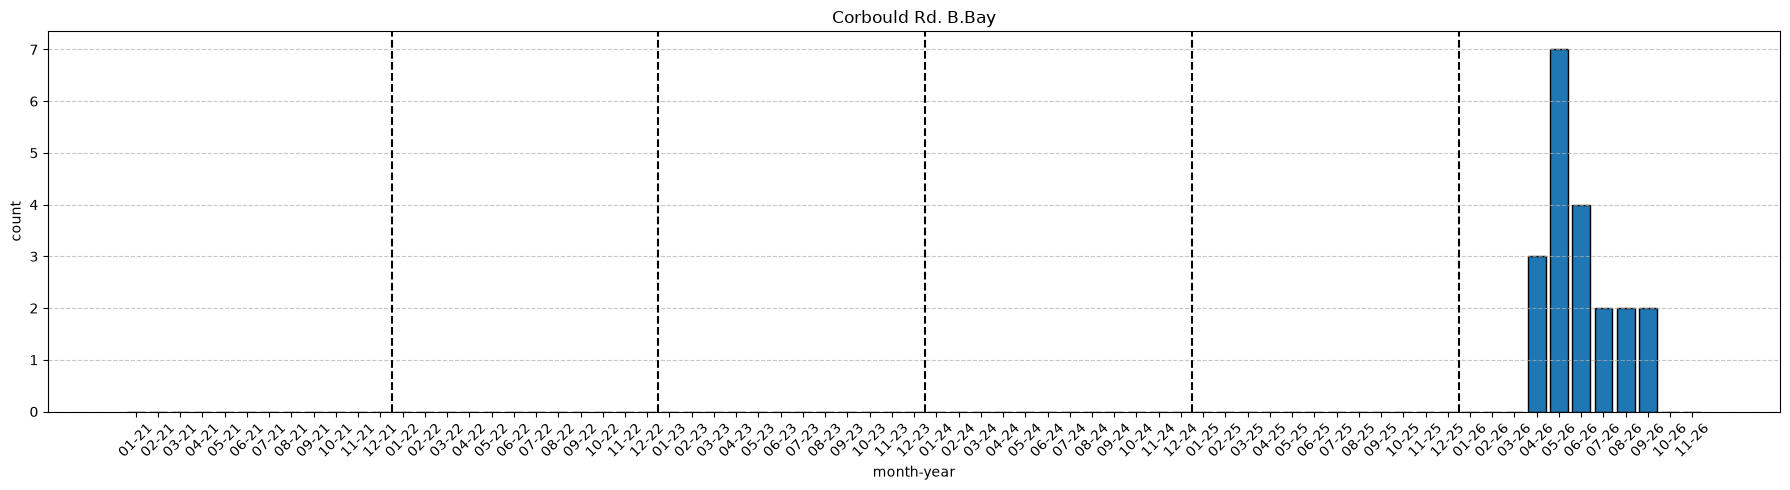

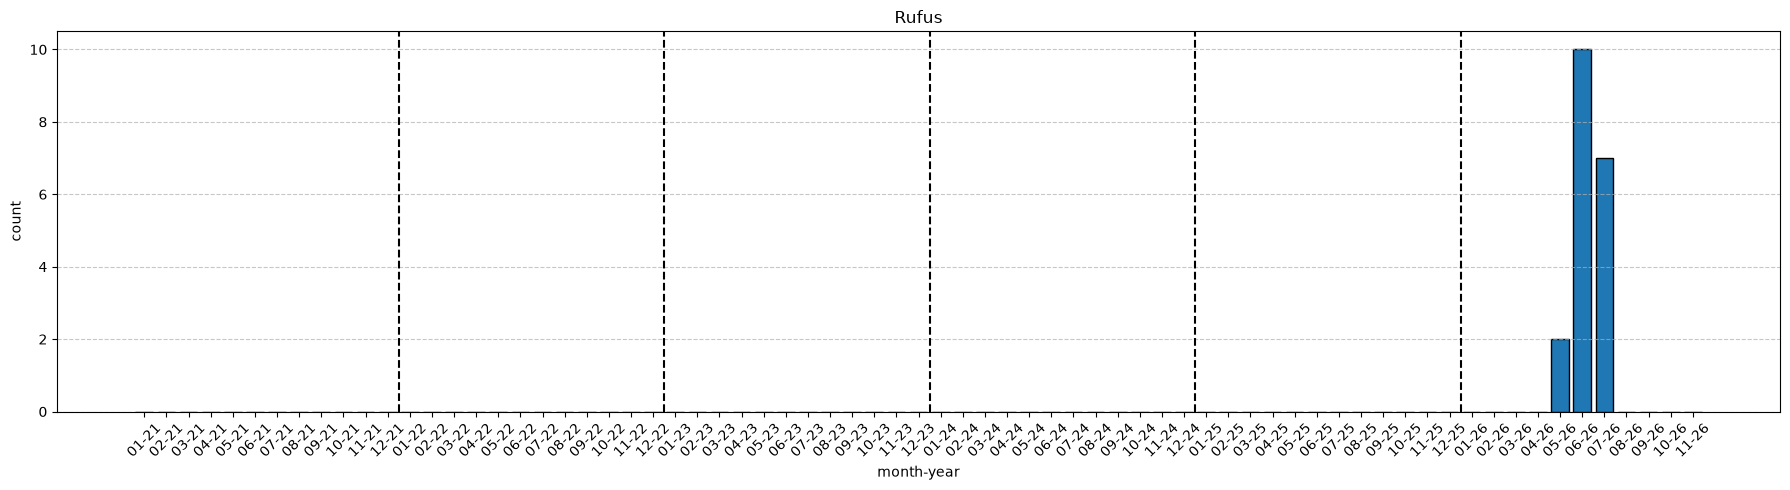

In [50]:
startdate = pd.to_datetime(df['startdate'])
months = pd.period_range(
    startdate.min().to_period('M'), startdate.max().to_period('M'), freq='M'
)
monthly_counts = (
    df.assign(month_year=startdate.dt.to_period('M'))
    .groupby(['spot', 'month_year'])
    .size()
)
top_spots = df['spot'].value_counts().head(20).index
positions = np.arange(len(months))

for spot in top_spots:
    counts = monthly_counts.reindex(
        pd.MultiIndex.from_product([[spot], months]), fill_value=0
    ).to_numpy()

    fig, ax = plt.subplots(figsize=(18, 5))
    ax.bar(positions, counts, edgecolor='black')
    ax.set_xticks(positions)
    ax.set_xticklabels(
        [month.strftime('%m-%y') for month in months], rotation=45
    )
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)

    for i, month in enumerate(months):
        if i > 0 and month.month == 1:
            ax.axvline(i - 0.5, color='black', linestyle='--')

    ax.set_xlabel('month-year')
    ax.set_ylabel('count')
    ax.set_title(spot)
    fig.tight_layout()
    plt.show()

In [67]:
pivot_pct

month,1,2,3,4,5,6,7,8,9,10,11,12
"Ross Bay (n=2,401)",2.540608,5.747605,8.121616,13.994169,16.659725,11.995002,13.286131,7.205331,6.580591,5.081216,4.248230,4.539775
Nitinat Lk (n=727),0.000000,0.000000,0.000000,0.550206,11.829436,20.495186,28.473177,27.372765,11.279230,0.000000,0.000000,0.000000
[Secret spot] (n=468),10.042735,10.256410,6.623932,6.623932,6.623932,10.897436,8.547009,8.760684,4.273504,9.401709,9.615385,8.333333
Cattle Pt (n=414),19.806763,16.666667,11.111111,11.352657,2.898551,0.483092,1.449275,2.415459,2.657005,12.560386,9.420290,9.178744
Clover Pt (n=407),6.388206,7.862408,8.845209,10.319410,15.233415,8.353808,9.090909,6.142506,5.896806,7.371007,7.125307,7.371007
Willows Bch (n=342),12.865497,14.619883,15.789474,9.649123,3.508772,2.339181,2.631579,0.292398,4.385965,11.988304,13.742690,8.187135
Comox Spit (n=325),7.692308,8.307692,12.923077,8.000000,10.461538,7.076923,4.000000,7.384615,6.153846,10.461538,8.000000,9.538462
Island View (n=157),10.828025,11.464968,13.375796,15.286624,1.910828,3.184713,1.910828,1.910828,5.732484,19.108280,10.191083,5.095541
China Ck (n=153),0.000000,0.000000,0.000000,0.653595,0.000000,24.836601,35.294118,34.640523,4.575163,0.000000,0.000000,0.000000
Pipers Lgn (n=134),0.746269,0.000000,4.477612,7.462687,13.432836,14.925373,13.432836,11.194030,16.417910,14.925373,2.985075,0.000000


In [68]:
pivot

month,1,2,3,4,5,6,7,8,9,10,11,12
spot,,,,,,,,,,,,
Ross Bay,61,138,195,336,400,288,319,173,158,122,102,109
Nitinat Lk,0,0,0,4,86,149,207,199,82,0,0,0
[Secret spot],47,48,31,31,31,51,40,41,20,44,45,39
Cattle Pt,82,69,46,47,12,2,6,10,11,52,39,38
Clover Pt,26,32,36,42,62,34,37,25,24,30,29,30
Willows Bch,44,50,54,33,12,8,9,1,15,41,47,28
Comox Spit,25,27,42,26,34,23,13,24,20,34,26,31
Island View,17,18,21,24,3,5,3,3,9,30,16,8
China Ck,0,0,0,1,0,38,54,53,7,0,0,0


In [70]:
pivot_pct

month,1,2,3,4,5,6,7,8,9,10,11,12
"Ross Bay (n=2,401)",2.540608,5.747605,8.121616,13.994169,16.659725,11.995002,13.286131,7.205331,6.580591,5.081216,4.248230,4.539775
Nitinat Lk (n=727),0.000000,0.000000,0.000000,0.550206,11.829436,20.495186,28.473177,27.372765,11.279230,0.000000,0.000000,0.000000
[Secret spot] (n=468),10.042735,10.256410,6.623932,6.623932,6.623932,10.897436,8.547009,8.760684,4.273504,9.401709,9.615385,8.333333
Cattle Pt (n=414),19.806763,16.666667,11.111111,11.352657,2.898551,0.483092,1.449275,2.415459,2.657005,12.560386,9.420290,9.178744
Clover Pt (n=407),6.388206,7.862408,8.845209,10.319410,15.233415,8.353808,9.090909,6.142506,5.896806,7.371007,7.125307,7.371007
Willows Bch (n=342),12.865497,14.619883,15.789474,9.649123,3.508772,2.339181,2.631579,0.292398,4.385965,11.988304,13.742690,8.187135
Comox Spit (n=325),7.692308,8.307692,12.923077,8.000000,10.461538,7.076923,4.000000,7.384615,6.153846,10.461538,8.000000,9.538462
Island View (n=157),10.828025,11.464968,13.375796,15.286624,1.910828,3.184713,1.910828,1.910828,5.732484,19.108280,10.191083,5.095541
China Ck (n=153),0.000000,0.000000,0.000000,0.653595,0.000000,24.836601,35.294118,34.640523,4.575163,0.000000,0.000000,0.000000
Pipers Lgn (n=134),0.746269,0.000000,4.477612,7.462687,13.432836,14.925373,13.432836,11.194030,16.417910,14.925373,2.985075,0.000000


In [79]:
df

,year,month,day,id,user,title,type,maxspeed100,maxspeed500,maxspeednm,...,dislikes,file_id,catid,alias,rating,avatar,spot,conditions,turncount,foilingturncount
0,2021,11,27,0,bwd,XL breakfast,Windfoil,13.32,11.64,4.79,...,0,105,31,xl-breakfast,5.0,NaN,Island View,SE 12-16,9,60
1,2021,1,1,1,tweezer,Drive of Fame,Windfoil,21.72,18.36,16.48,...,0,116,31,drive-of-fame,0.0,NaN,Island View,SE 15-23,82,84
2,2021,1,1,2,bwd,Well hello 2021,Windfoil,13.43,12.34,11.79,...,0,117,31,well-hello-2021,0.0,NaN,Island View,SE 15-25,91,77
3,2021,1,2,3,tweezer,Flocking Ducks,Windfoil,23.42,17.77,16.85,...,0,118,31,flocking-ducks,0.0,NaN,Willows Bch,SE 12-20,57,89
4,2021,1,3,4,tweezer,Boat Chase,Windfoil,21.91,19.54,18.01,...,0,119,31,boat-chase,0.0,NaN,Willows Bch,SSE 12-18,65,95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6165,2026,11,16,1549,tweezer,Race faces,Parawing,17.03,14.21,0.00,...,0,6627,55,race-faces-1,0.0,NaN,Ka'a,ENE 25-40,176,76
6166,2026,11,17,1550,thepope,Calmer Kaa,Wingfoil,16.75,14.58,0.00,...,0,6628,33,calmer-kaa,0.0,NaN,Ka'a,ENE 18-28,210,88
6167,2026,11,17,1551,tweezer,Leroy Brown,Parawing,18.40,16.07,0.00,...,0,6629,55,leroy-brown,0.0,NaN,Ka'a,ENE 20-30,146,66
6168,2026,11,17,1552,rup_dogg,Ka’a_2026-11-17_rup_dogg,Parawing,16.52,14.50,0.00,...,0,6630,55,kaa2026-11-17rupdogg,0.0,NaN,Ka'a,ENE 20-28,104,91


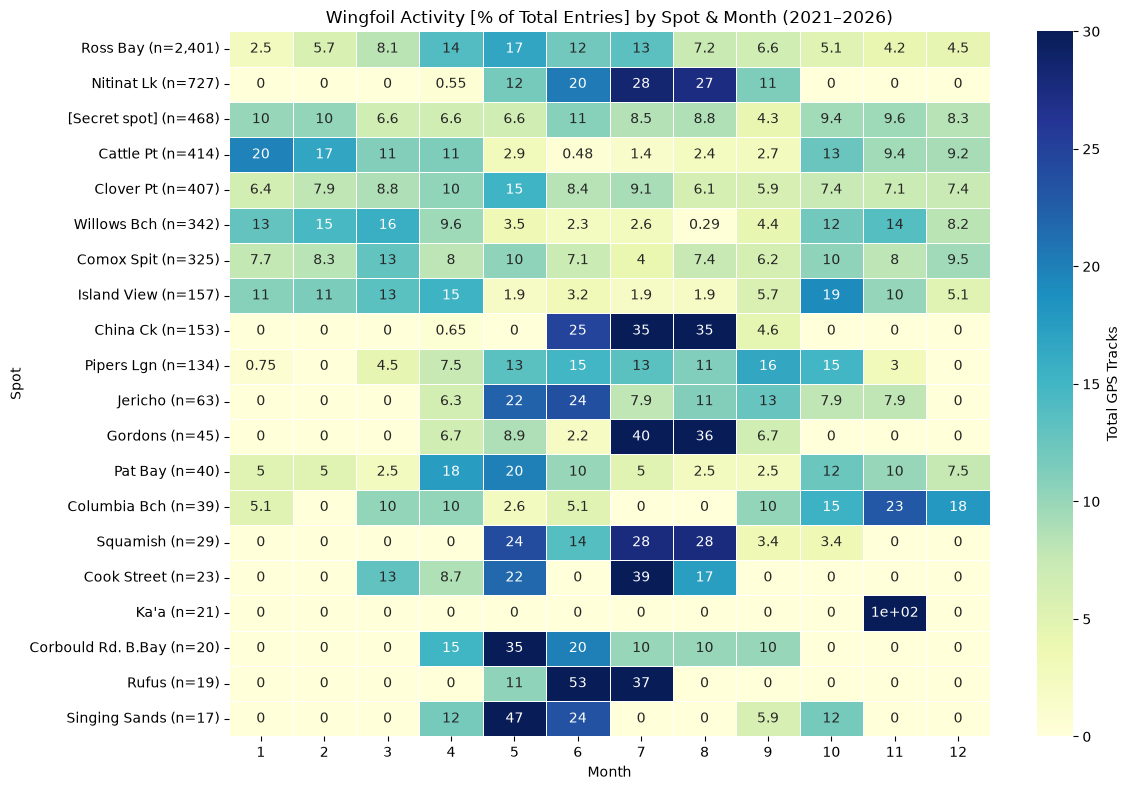

In [82]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('./Data/standardized_data.csv')

df = df[df['spot'] != 'The Hatchery']


# 1. Extract month order (Jan–Dec)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
# df['Month'] = pd.Categorical(df['Date'].str[:3], categories=months, ordered=True)

# 2. Keep top 20 most active spots (excluding blank/[Secret spot] if desired)
top_spots = df['spot'].value_counts().head(20).index
pivot = (
    df[df['spot'].isin(top_spots)]
    .pivot_table(index='spot', columns='month', values='id', aggfunc='count', fill_value=0, observed=False)
    .loc[top_spots]  # preserves ranking from most active at top to least at bottom
)
pivot = pivot.reindex(columns=range(1, 13), fill_value=0)
pivot.columns = months

# # 3. Normalize each row to % of that spot's total tracks
row_totals = pivot.sum(axis=1)
pivot_pct = pivot.div(row_totals, axis=0) * 100
pivot_pct.index = [f"{spot} (n={n:,})" for spot, n in row_totals.items()]

# 3. Plot heatmap
plt.figure(figsize=(12, 8))
ax = sns.heatmap(pivot_pct, cmap='YlGnBu', annot=True, linewidths=0.5, cbar_kws={'label': 'Total GPS Tracks'}, vmax=30)
ax.set_xticklabels(months, rotation=45, ha='right')
plt.title('Wingfoil Activity [% of Total Entries] by Spot & Month (2021–2026)')
plt.xlabel('Month')
plt.ylabel('Spot')
plt.tight_layout()
plt.show()
